# 09 — Copula and DCC Dependence

**Tail Risk Adequacy**
High_Magus_of_Risk

---

## Objective

Notebooks 01-08 are univariate: each portfolio is one return series, so the
equity-bond *dependence* is locked into the fixed portfolio weights. The
report's headline 2022 finding — equities and bonds falling together when
the diversification benefit was most needed — is a dependence event that a
univariate model can only describe *ex post*.

This notebook closes that gap with two jointly-modelled engines:

- **Engle (2002) Dynamic Conditional Correlation (DCC(1,1))** on the
  standardised residuals of univariate GARCH fits to the equity and bond
  legs. Produces a time-varying conditional correlation ρ_t.
- **Student-t copula tail dependence** — the limiting joint-crash
  probability λ between two heavy-tailed series with correlation ρ. The
  Gaussian copula gives λ = 0 for any ρ < 1; the t-copula does not.


---
## 1  Setup

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, 'src')
from garch_fhs import fit_garch_window
from dcc_garch import estimate_dcc, t_copula_tail_dependence

pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams.update({'figure.figsize': (14, 5), 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})
print('Imports OK.')

Imports OK.


---
## 2  Load returns

In [2]:
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)
r_eq = returns['SP500_ret'].dropna()
r_bd = returns['VBMFX_ret'].dropna()

# Align on common dates (defensive; they already share an index)
common = r_eq.index.intersection(r_bd.index)
r_eq = r_eq.loc[common]
r_bd = r_bd.loc[common]

print(f'Sample        : {len(common):,} trading days, '
      f'{common[0].date()} to {common[-1].date()}')
print(f'Unconditional corr(SP500, VBMFX) full sample: {r_eq.corr(r_bd):+.3f}')

with open('data/stress_windows.json') as f:
    stress_windows = json.load(f)
print(f'Stress windows: {list(stress_windows.keys())}')

Sample        : 7,485 trading days, 1996-05-14 to 2026-04-01
Unconditional corr(SP500, VBMFX) full sample: -0.152
Stress windows: ['DotCom_2000_2003', 'GFC', 'COVID', 'Rate_Hikes_2022']


---
## 3  Univariate GARCH per leg

Fit a zero-mean GARCH(1,1) to each return series. The DCC step takes the
**standardised residuals** z_t = r_t / σ_t (each approximately iid with
mean 0 and variance 1) as input. We use the full sample for the in-sample
fit; the dependence structure across the four crisis regimes is what
matters here, not a rolling out-of-sample backtest.

In [3]:
res_eq = fit_garch_window(r_eq)
res_bd = fit_garch_window(r_bd)

print('--- Equity GARCH(1,1) parameters ---')
print(res_eq.params.round(4).to_string())
print()
print('--- Bond GARCH(1,1) parameters ---')
print(res_bd.params.round(4).to_string())

z_eq = pd.Series(res_eq.std_resid.values, index=r_eq.index, name='z_eq')
z_bd = pd.Series(res_bd.std_resid.values, index=r_bd.index, name='z_bd')

print(f'\nStandardised residuals')
print(f'  z_eq: mean={z_eq.mean():+.3f}, std={z_eq.std():.3f}')
print(f'  z_bd: mean={z_bd.mean():+.3f}, std={z_bd.std():.3f}')
print(f'  cross-correlation of z_eq, z_bd: {z_eq.corr(z_bd):+.3f}')

--- Equity GARCH(1,1) parameters ---
omega      0.0241
alpha[1]   0.1160
beta[1]    0.8670

--- Bond GARCH(1,1) parameters ---
omega      0.0011
alpha[1]   0.0424
beta[1]    0.9433

Standardised residuals
  z_eq: mean=+0.042, std=0.999
  z_bd: mean=+0.068, std=0.995
  cross-correlation of z_eq, z_bd: -0.148


---
## 4  Dynamic Conditional Correlation

In [4]:
dcc = estimate_dcc(z_eq.values, z_bd.values)

print('DCC(1,1) estimates:')
print(f'  a (innovation weight)       = {dcc["a"]:.4f}')
print(f'  b (persistence)             = {dcc["b"]:.4f}')
print(f'  a + b (total persistence)   = {dcc["persistence"]:.4f}')
print(f'  rho_bar (unconditional ρ)   = {dcc["rho_bar"]:+.4f}')
print(f'  n                           = {dcc["n"]:,}')

DCC(1,1) estimates:
  a (innovation weight)       = 0.0366
  b (persistence)             = 0.9533
  a + b (total persistence)   = 0.9899
  rho_bar (unconditional ρ)   = -0.1481
  n                           = 7,485


### 4.1  ρ_t through the crisis regimes

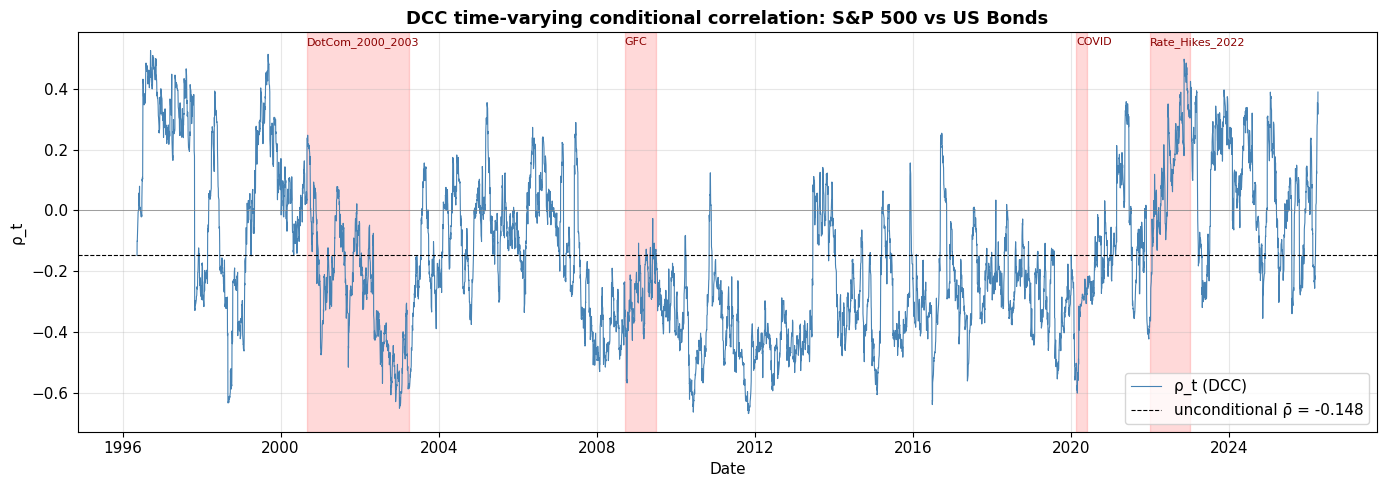

--- Mean and peak ρ_t by regime ---
  DotCom_2000_2003        : mean ρ_t = -0.261, max ρ_t = +0.248, n = 637
  GFC                     : mean ρ_t = -0.273, max ρ_t = -0.026, n = 200
  COVID                   : mean ρ_t = -0.356, max ρ_t = -0.226, n = 72
  Rate_Hikes_2022         : mean ρ_t = +0.142, max ρ_t = +0.498, n = 251


In [5]:
rho_t = pd.Series(dcc['rho_t'], index=z_eq.index, name='rho_t')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(rho_t.index, rho_t.values, lw=0.8, color='steelblue', label='ρ_t (DCC)')
ax.axhline(dcc['rho_bar'], color='black', lw=0.8, ls='--',
           label=f'unconditional ρ̄ = {dcc["rho_bar"]:+.3f}')
ax.axhline(0, color='gray', lw=0.5)

for name, w in stress_windows.items():
    ax.axvspan(pd.Timestamp(w['start']), pd.Timestamp(w['end']),
               alpha=0.15, color='red')
    ax.text(pd.Timestamp(w['start']), ax.get_ylim()[1] * 0.93, name,
            fontsize=8, color='darkred')

ax.set_title('DCC time-varying conditional correlation: S&P 500 vs US Bonds',
             fontsize=13, fontweight='bold')
ax.set_ylabel('ρ_t')
ax.set_xlabel('Date')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('--- Mean and peak ρ_t by regime ---')
for name, w in stress_windows.items():
    m = (rho_t.index >= pd.Timestamp(w['start'])) & (rho_t.index <= pd.Timestamp(w['end']))
    print(f'  {name:24s}: mean ρ_t = {rho_t[m].mean():+.3f}, '
          f'max ρ_t = {rho_t[m].max():+.3f}, n = {int(m.sum())}')

---
## 5  Student-t copula tail dependence

The DCC describes how correlation moves through time. The Student-t copula
adds the missing piece: the **joint-crash probability** given heavy tails.
For two t-distributed margins with correlation ρ and degrees of freedom ν,
the lower (= upper) tail-dependence coefficient is

$$\lambda \;=\; 2 \, T_{\nu+1}\!\left( -\sqrt{\tfrac{(\nu+1)(1-\rho)}{1+\rho}}\, \right)$$

i.e. the probability that bonds are in their lower tail given equities are.
The Gaussian copula has λ = 0 for any ρ < 1; the t-copula has λ > 0 — which
is why it is the right tool for regime-relevant joint-crash risk.

In [6]:
calm_rho = float(rho_t.iloc[:1000].mean())   # earliest 1000 days
peak_rho = float(rho_t.max())                 # peak ρ_t over the full sample

print(f'Calm-period ρ (early-sample mean): {calm_rho:+.3f}')
print(f'Peak ρ over the sample           : {peak_rho:+.3f}')
print()
print('Tail-dependence coefficient λ at the Student-t copula:')
print(f'{"ν":>4s}  {"λ(calm ρ)":>12s}  {"λ(peak ρ)":>12s}')
for nu in (4, 6, 10, 30):
    lam_calm = t_copula_tail_dependence(calm_rho, nu)
    lam_peak = t_copula_tail_dependence(peak_rho, nu)
    print(f'{nu:>4d}  {lam_calm:>12.4f}  {lam_peak:>12.4f}')

Calm-period ρ (early-sample mean): +0.096
Peak ρ over the sample           : +0.527

Tail-dependence coefficient λ at the Student-t copula:
   ν     λ(calm ρ)     λ(peak ρ)
   4        0.0980        0.2684
   6        0.0473        0.1843
  10        0.0118        0.0919
  30        0.0000        0.0041


---
## 6  Implications for portfolio risk

The time-varying correlation feeds directly into portfolio variance:

$$\sigma_p^2(t) \;=\; w_{eq}^2\,\sigma_{eq}^2(t) + w_{bd}^2\,\sigma_{bd}^2(t) + 2\,w_{eq}\,w_{bd}\,\sigma_{eq}(t)\,\sigma_{bd}(t)\,\rho(t)$$

Using the DCC ρ_t and the GARCH conditional volatilities of each leg, the
plot below shows the implied FO equity/bond sleeve volatility
through time — and what they would have been under the long-run unconditional
correlation ρ̄ instead.

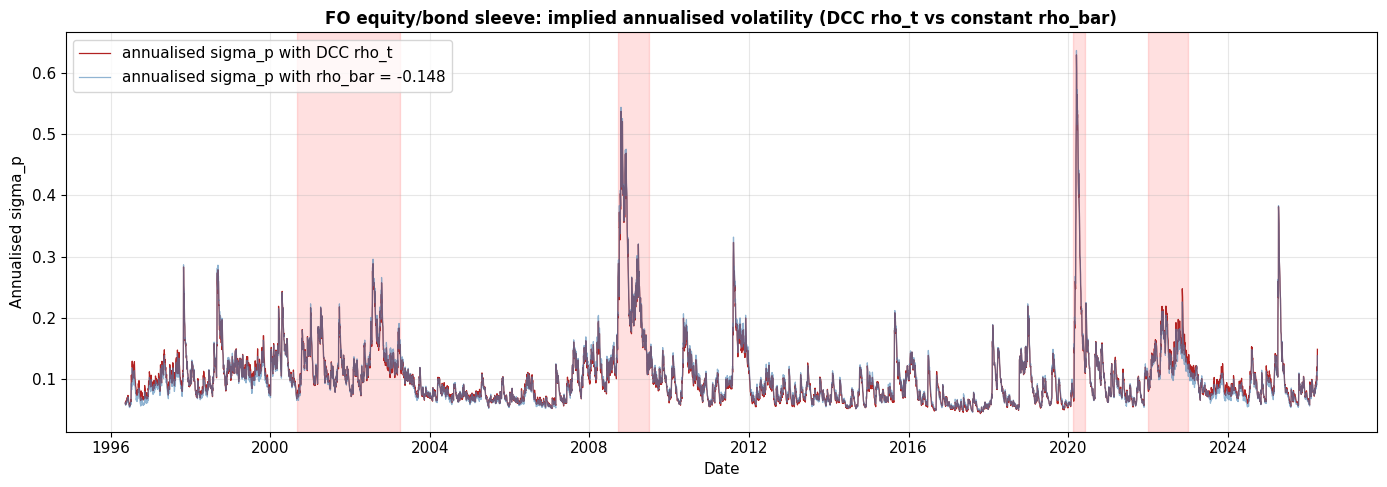

In [7]:
SCALE = 100.0   # arch fits returns in pct scale; convert back
sigma_eq = pd.Series(res_eq.conditional_volatility.values / SCALE, index=r_eq.index)
sigma_bd = pd.Series(res_bd.conditional_volatility.values / SCALE, index=r_bd.index)

def port_vol(w_eq, w_bd, rho_series):
    return np.sqrt(w_eq ** 2 * sigma_eq ** 2
                   + w_bd ** 2 * sigma_bd ** 2
                   + 2 * w_eq * w_bd * sigma_eq * sigma_bd * rho_series)

# FO policy equity/bond weights (40/25), renormalised to the equity-bond pair the DCC covers
W_EQ, W_BD = 0.615, 0.385
sigma_fo_dcc    = port_vol(W_EQ, W_BD, rho_t)
sigma_fo_uncond = port_vol(W_EQ, W_BD, dcc['rho_bar'])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sigma_fo_dcc.index, sigma_fo_dcc.values * np.sqrt(252), lw=0.9, color='firebrick',
        label='annualised sigma_p with DCC rho_t')
ax.plot(sigma_fo_uncond.index, sigma_fo_uncond.values * np.sqrt(252), lw=0.9, color='steelblue',
        alpha=0.6, label=f"annualised sigma_p with rho_bar = {dcc['rho_bar']:+.3f}")
for name, w in stress_windows.items():
    ax.axvspan(pd.Timestamp(w['start']), pd.Timestamp(w['end']), alpha=0.12, color='red')
ax.set_title('FO equity/bond sleeve: implied annualised volatility (DCC rho_t vs constant rho_bar)',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Annualised sigma_p'); ax.set_xlabel('Date'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

---
## 7  Save outputs

DCC artefacts (ρ_t series, parameters, conditional leg volatilities and
implied portfolio volatilities) are saved to `data/dcc/` so notebook 10
(and later notebooks) can pick them up without re-fitting.

In [8]:
out_dir = 'data/dcc'
os.makedirs(out_dir, exist_ok=True)

rho_t.to_csv(f'{out_dir}/rho_t.csv', header=True)

pd.DataFrame({'a': [dcc['a']], 'b': [dcc['b']],
              'persistence': [dcc['persistence']],
              'rho_bar': [dcc['rho_bar']], 'n': [dcc['n']]}
            ).to_csv(f'{out_dir}/dcc_params.csv', index=False)

pd.DataFrame({'sigma_eq': sigma_eq, 'sigma_bd': sigma_bd}
            ).to_csv(f'{out_dir}/sigma_legs.csv')

pd.DataFrame({'sigma_fo_dcc': sigma_fo_dcc,
              'sigma_fo_uncond': sigma_fo_uncond}
            ).to_csv(f'{out_dir}/portfolio_sigma.csv')

td_rows = []
for nu in (4, 6, 10, 30):
    td_rows.append({'nu': nu,
                    'lambda_calm': t_copula_tail_dependence(calm_rho, nu),
                    'lambda_peak': t_copula_tail_dependence(peak_rho, nu)})
pd.DataFrame(td_rows).to_csv(f'{out_dir}/tail_dependence.csv', index=False)

print(f'Saved DCC outputs to ./{out_dir}/')
print('  rho_t.csv, dcc_params.csv, sigma_legs.csv, portfolio_sigma.csv, tail_dependence.csv')

Saved DCC outputs to ./data/dcc/
  rho_t.csv, dcc_params.csv, sigma_legs.csv, portfolio_sigma.csv, tail_dependence.csv
